<a href="https://www.kaggle.com/code/qwerty29544/cv-1-fashion-mnist-cnn?scriptVersionId=365945528" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# PyTorch. От двумерной свёртки к FashionMNIST

Разберём свёртку на небольших матрицах и соберём сеть через `nn.Sequential`.
Затем обучим её распознавать одежду на FashionMNIST.
Сравним свёрточную и полносвязную модели по числу параметров, времени вычислений и качеству.

## Импорт

In [1]:
from copy import deepcopy
from time import perf_counter
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from IPython.display import display

torch.manual_seed(42)
torch.set_printoptions(precision=3, sci_mode=False)

## 1. Изображение и окно свёртки

### 1.1. Представим изображение матрицей

Одноканальное изображение хранит одно число на каждый пиксель.
Для первого примера достаточно матрицы $5\times5$.
В PyTorch пакет таких изображений имеет форму `(N, C, H, W)`.
Здесь `N` — число изображений, `C` — число каналов, `H` и `W` — высота и ширина [1].

Добавим две оси длины один.
Получим одно изображение с одним каналом.

Матрица (5, 5)
Пакет (1, 1, 5, 5)


,0,1,2,3,4
0,0.0,0.0,1.0,1.0,1.0
1,0.0,0.0,1.0,1.0,1.0
2,0.0,0.0,1.0,1.0,1.0
3,0.0,0.0,1.0,1.0,1.0
4,0.0,0.0,1.0,1.0,1.0


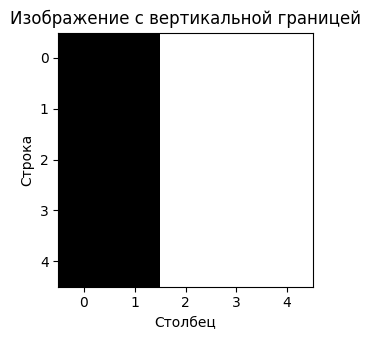

In [2]:
image = torch.tensor([
    [0., 0., 1., 1., 1.],
    [0., 0., 1., 1., 1.],
    [0., 0., 1., 1., 1.],
    [0., 0., 1., 1., 1.],
    [0., 0., 1., 1., 1.],
])
x = image.unsqueeze(0).unsqueeze(0)

print("Матрица", tuple(image.shape))
print("Пакет", tuple(x.shape))
display(pd.DataFrame(image.numpy()))

plt.figure(figsize=(4, 3.5))
plt.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
plt.xticks(range(5))
plt.yticks(range(5))
plt.xlabel("Столбец")
plt.ylabel("Строка")
plt.title("Изображение с вертикальной границей")
plt.tight_layout()
plt.show()

### 1.2. Вычислим один отклик

Возьмём ядро $3\times3$ и совместим его с левым верхним окном изображения.
Перемножим соответствующие элементы и сложим произведения.
Сдвиг окна даст следующий элемент выходной карты.

$$a_{i,j}=\sum_{u=0}^{2}\sum_{v=0}^{2}K_{u,v}X_{i+u,j+v}.$$

`Conv2d` использует взаимную корреляцию, то есть не переворачивает ядро [1].
В нейросетях эту операцию принято называть свёрткой.
Отклик похож на оценку совпадения с шаблоном, но не является нормированным коэффициентом корреляции.

In [3]:
kernel = torch.tensor([
    [-1., 0., 1.],
    [-1., 0., 1.],
    [-1., 0., 1.],
])
window = image[:3, :3]

print("Окно")
display(pd.DataFrame(window.numpy()))
print("Ядро")
display(pd.DataFrame(kernel.numpy()))
print("Поэлементное произведение")
display(pd.DataFrame((window * kernel).numpy()))
print("Сумма произведений", (window * kernel).sum().item())

Окно


,0,1,2
0,0.0,0.0,1.0
1,0.0,0.0,1.0
2,0.0,0.0,1.0


Ядро


,0,1,2
0,-1.0,0.0,1.0
1,-1.0,0.0,1.0
2,-1.0,0.0,1.0


Поэлементное произведение


,0,1,2
0,-0.0,0.0,1.0
1,-0.0,0.0,1.0
2,-0.0,0.0,1.0


Сумма произведений 3.0


### 1.3. Передвинем окно по всей матрице

Пока не добавляем рамку и сдвигаем окно на один пиксель.
В каждом направлении доступны три положения.
Выходная карта будет иметь размер $3\times3$.

Сначала запишем вычисление циклом.
Затем передадим то же ядро в `F.conv2d` и в слой `nn.Conv2d`.
Функция получает готовые веса, а слой хранит веса как обучаемые параметры [1, 2].

In [4]:
manual = torch.zeros(3, 3)
for row in range(3):
    for column in range(3):
        window = image[row:row + 3, column:column + 3]
        manual[row, column] = (window * kernel).sum()

weight = kernel[None, None, :, :]  # (C_out, C_in, kH, kW)
functional_result = F.conv2d(x, weight)

conv = nn.Conv2d(1, 1, kernel_size=3, bias=False)
with torch.no_grad():
    conv.weight.copy_(weight)
layer_result = conv(x)

print("Карта, вычисленная циклом")
display(pd.DataFrame(manual.numpy()))
print("F.conv2d", tuple(functional_result.shape))
print("nn.Conv2d", tuple(layer_result.shape))
print("Максимальное расхождение", (manual - layer_result[0, 0]).abs().max().item())
print("Обучаемых весов", conv.weight.numel())

Карта, вычисленная циклом


,0,1,2
0,3.0,3.0,0.0
1,3.0,3.0,0.0
2,3.0,3.0,0.0


F.conv2d (1, 1, 3, 3)
nn.Conv2d (1, 1, 3, 3)
Максимальное расхождение 0.0
Обучаемых весов 9


## 2. Размер карты и режимы свёртки

### 2.1. Padding, stride и dilation

`padding` добавляет рамку вокруг входной карты.
`stride` задаёт шаг между соседними положениями окна.
`dilation` задаёт расстояние между выбранными элементами внутри окна [1].
При `dilation=2` ядро $3\times3$ охватывает область $5\times5$, но по-прежнему содержит девять весов.

Размер выхода по высоте равен

$$H_{out}=\left\lfloor\frac{H_{in}+2p-d(k-1)-1}{s}\right\rfloor+1.$$

Для ширины используется такая же формула.
Здесь $p$ — padding, $s$ — stride, $d$ — dilation, $k$ — размер ядра по выбранной оси.
Параметры по высоте и ширине могут различаться.

In [5]:
x7 = torch.arange(49, dtype=torch.float32).reshape(1, 1, 7, 7)
settings = [
    ("Без рамки", 3, 0, 1, 1),
    ("Сохранение размера", 3, 1, 1, 1),
    ("Шаг 2", 3, 1, 2, 1),
    ("Разреженное ядро", 3, 0, 1, 2),
    ("Разреженное ядро с рамкой", 3, 2, 1, 2),
]
rows = []
for name, k, p, s, d in settings:
    layer = nn.Conv2d(1, 1, k, padding=p, stride=s, dilation=d)
    predicted_size = (7 + 2 * p - d * (k - 1) - 1) // s + 1
    rows.append({
        "Режим": name, "k": k, "p": p, "s": s, "d": d,
        "По формуле": predicted_size, "Форма выхода": tuple(layer(x7).shape),
    })
display(pd.DataFrame(rows))

,Режим,k,p,s,d,По формуле,Форма выхода
0,Без рамки,3,0,1,1,5,"(1, 1, 5, 5)"
1,Сохранение размера,3,1,1,1,7,"(1, 1, 7, 7)"
2,Шаг 2,3,1,2,1,4,"(1, 1, 4, 4)"
3,Разреженное ядро,3,0,1,2,3,"(1, 1, 3, 3)"
4,Разреженное ядро с рамкой,3,2,1,2,7,"(1, 1, 7, 7)"


### 2.2. Что находится в рамке

По умолчанию `padding_mode="zeros"` заполняет рамку нулями.
`reflect` отражает значения около границы, `replicate` повторяет крайний пиксель.
`circular` переносит значения с противоположной стороны [1].
Выбор рамки меняет отклики около края изображения.

`padding="valid"` означает отсутствие рамки.
`padding="same"` сохраняет пространственный размер, но в `Conv2d` поддерживается только при `stride=1` [1].

In [6]:
small = torch.arange(1, 10, dtype=torch.float32).reshape(1, 1, 3, 3)
for mode in ["zeros", "reflect", "replicate", "circular"]:
    if mode == "zeros":
        padded = F.pad(small, (1, 1, 1, 1), mode="constant", value=0)
    else:
        padded = F.pad(small, (1, 1, 1, 1), mode=mode)
    print(mode)
    display(pd.DataFrame(padded[0, 0].numpy().astype(int)))

same = nn.Conv2d(1, 2, 3, padding="same", padding_mode="reflect")
valid = nn.Conv2d(1, 2, 3, padding="valid")
print("same", tuple(same(x7).shape), "valid", tuple(valid(x7).shape))

zeros


,0,1,2,3,4
0,0,0,0,0,0
1,0,1,2,3,0
2,0,4,5,6,0
3,0,7,8,9,0
4,0,0,0,0,0


reflect


,0,1,2,3,4
0,5,4,5,6,5
1,2,1,2,3,2
2,5,4,5,6,5
3,8,7,8,9,8
4,5,4,5,6,5


replicate


,0,1,2,3,4
0,1,1,2,3,3
1,1,1,2,3,3
2,4,4,5,6,6
3,7,7,8,9,9
4,7,7,8,9,9


circular


,0,1,2,3,4
0,9,7,8,9,7
1,3,1,2,3,1
2,6,4,5,6,4
3,9,7,8,9,7
4,3,1,2,3,1


same (1, 2, 7, 7) valid (1, 2, 5, 5)


### 2.3. Не смешиваем шаг и разреженность

При `stride=2` пропускаем часть положений всего окна.
При `dilation=2` пропускаем позиции внутри каждого окна.
Разреженная свёртка увеличивает охват без увеличения числа весов.
Сохранить при этом размер карты можно подходящей рамкой.

In [7]:
print("Обычное окно 3 × 3")
display(pd.DataFrame(x7[0, 0, :3, :3].numpy()))
print("Девять выбранных элементов при dilation=2")
display(pd.DataFrame(x7[0, 0, :5:2, :5:2].numpy()))

weight = torch.ones(1, 1, 3, 3)
print("Шаг 2, dilation 1")
display(pd.DataFrame(F.conv2d(x7, weight, stride=2)[0, 0].numpy()))
print("Шаг 1, dilation 2")
display(pd.DataFrame(F.conv2d(x7, weight, dilation=2)[0, 0].numpy()))

Обычное окно 3 × 3


,0,1,2
0,0.0,1.0,2.0
1,7.0,8.0,9.0
2,14.0,15.0,16.0


Девять выбранных элементов при dilation=2


,0,1,2
0,0.0,2.0,4.0
1,14.0,16.0,18.0
2,28.0,30.0,32.0


Шаг 2, dilation 1


,0,1,2
0,72.0,90.0,108.0
1,198.0,216.0,234.0
2,324.0,342.0,360.0


Шаг 1, dilation 2


,0,1,2
0,144.0,153.0,162.0
1,207.0,216.0,225.0
2,270.0,279.0,288.0


## 3. Входные и выходные карты

### 3.1. Обычная свёртка смешивает каналы

Цветное изображение обычно имеет три входных канала.
После первого слоя каналы становятся картами вычисленных признаков.
Их число задаётся через `out_channels` и не обязано совпадать с числом входных каналов.

При `groups=1` каждый выходной канал использует все входные карты [1].
Сначала получаются отдельные отклики по входным каналам.
Затем они складываются и к сумме прибавляется одно смещение выходного канала.

$$Y_o=b_o+\sum_{c=0}^{C_{in}-1}W_{o,c}\star X_c.$$

Веса имеют форму `(C_out, C_in, kH, kW)`.
Один набор весов используется во всех пространственных положениях.

In [8]:
x_channels = torch.stack([
    torch.arange(1, 10, dtype=torch.float32).reshape(3, 3),
    torch.ones(3, 3) * 10,
])[None, :, :, :]

conv_channels = nn.Conv2d(2, 2, kernel_size=2, bias=True)
with torch.no_grad():
    conv_channels.weight[0, 0].fill_(1)
    conv_channels.weight[0, 1].fill_(0.5)
    conv_channels.weight[1, 0].fill_(-1)
    conv_channels.weight[1, 1].fill_(0.25)
    conv_channels.bias.copy_(torch.tensor([1., -2.]))

contributions = (
    x_channels[0, :, :2, :2] * conv_channels.weight[0]
).sum(dim=(1, 2))
y_channels = conv_channels(x_channels)
print("Вход", tuple(x_channels.shape))
print("Веса", tuple(conv_channels.weight.shape))
print("Выход", tuple(y_channels.shape))
print("Вклады двух входных каналов в первый выход", contributions.detach())
print("Сумма со смещением", (contributions.sum() + conv_channels.bias[0]).item())
print("Тот же элемент выхода слоя", y_channels[0, 0, 0, 0].item())

Вход (1, 2, 3, 3)
Веса (2, 2, 2, 2)
Выход (1, 2, 2, 2)
Вклады двух входных каналов в первый выход tensor([12., 20.])
Сумма со смещением 33.0
Тот же элемент выхода слоя 33.0


### 3.2. Групповая и поканальная свёртки

Обычная свёртка нужна, когда пространственный признак зависит от сочетания входных карт.
`groups=2` делит каналы на две независимые группы.
Числа входных и выходных каналов должны делиться на число групп [1].

В поканальной свёртке, или *depthwise*, `groups=C_in`.
Каждая входная карта обрабатывается отдельно.
При `C_out=C_in` на каждую карту приходится одно ядро.
Можно получить несколько выходов на входную карту, если `C_out` кратно `C_in` [1].

Такие слои ограничивают связи между каналами и уменьшают число весов.
Ниже изменим только первый входной канал и посмотрим, какие выходы отреагируют.

In [9]:
variants = {
    "Обычная": nn.Conv2d(4, 8, 3, padding=1, bias=False),
    "Две группы": nn.Conv2d(4, 8, 3, padding=1, groups=2, bias=False),
    "Depthwise": nn.Conv2d(4, 4, 3, padding=1, groups=4, bias=False),
}
x_base = torch.zeros(1, 4, 5, 5)
x_changed = x_base.clone()
x_changed[:, 0] = 1
rows = []
for name, layer in variants.items():
    with torch.no_grad():
        layer.weight.fill_(1)
        difference = (layer(x_changed) - layer(x_base)).abs().sum(dim=(0, 2, 3))
    rows.append({
        "Слой": name,
        "Веса": tuple(layer.weight.shape),
        "Число весов": layer.weight.numel(),
        "Изменились выходные каналы": torch.where(difference > 0)[0].tolist(),
    })
display(pd.DataFrame(rows))

,Слой,Веса,Число весов,Изменились выходные каналы
0,Обычная,"(8, 4, 3, 3)",288,"[0, 1, 2, 3, 4, 5, 6, 7]"
1,Две группы,"(8, 2, 3, 3)",144,"[0, 1, 2, 3]"
2,Depthwise,"(4, 1, 3, 3)",36,[0]


### 3.3. Свёртка 1 × 1 и разделение двух операций

Ядро $1\times1$ не сравнивает соседние пиксели.
Оно смешивает каналы в одной позиции.
Такая свёртка называется *pointwise* и позволяет менять число карт.

Связка depthwise и pointwise сначала обрабатывает пространство внутри каждой карты, затем смешивает карты.
Её называют разделимой по глубине свёрткой.
Этот приём используется в компактных сетях [3].

Без смещений обычный слой содержит $k^2C_{in}C_{out}$ весов.
Связка с одним depthwise-ядром на канал содержит $k^2C_{in}+C_{in}C_{out}$ весов.
Это более ограниченная параметризация, а не точная замена любой обычной свёртки.

In [10]:
pointwise = nn.Conv2d(4, 6, kernel_size=1, bias=False)
x_point = torch.randn(1, 4, 3, 3)
manual_point = pointwise.weight[:, :, 0, 0] @ x_point[0, :, 1, 1]
layer_point = pointwise(x_point)[0, :, 1, 1]
print("Максимальное расхождение в одной позиции", (manual_point - layer_point).abs().max().item())

ordinary = nn.Conv2d(16, 32, 3, padding=1, bias=False)
separable = nn.Sequential(
    nn.Conv2d(16, 16, 3, padding=1, groups=16, bias=False),
    nn.Conv2d(16, 32, 1, bias=False),
)
display(pd.DataFrame({
    "Вариант": ["Обычная 3 × 3", "Depthwise 3 × 3 + pointwise 1 × 1"],
    "Число весов": [sum(p.numel() for p in ordinary.parameters()),
                     sum(p.numel() for p in separable.parameters())],
    "Расчёт": ["9 × 16 × 32", "9 × 16 + 16 × 32"],
}))

Максимальное расхождение в одной позиции 5.960464477539063e-08


,Вариант,Число весов,Расчёт
0,Обычная 3 × 3,4608,9 × 16 × 32
1,Depthwise 3 × 3 + pointwise 1 × 1,656,9 × 16 + 16 × 32


## 4. Pooling2d

### 4.1. Максимум и среднее внутри окна

Pooling заменяет небольшую область одним значением.
`MaxPool2d` берёт максимум, `AvgPool2d` — среднее [4, 5].
Операция выполняется отдельно для каждого канала.
Обучаемых весов в этих слоях нет.

Окно $2\times2$ с шагом 2 уменьшает высоту и ширину вдвое, если они чётные.
Это уменьшает объём последующих вычислений.
Часть информации о точном положении и мелких деталях при этом теряется.

In [11]:
pool_input = torch.tensor([
    [1., 2., 5., 6.],
    [3., 4., 7., 8.],
    [9., 10., 13., 14.],
    [11., 12., 15., 16.],
])[None, None, :, :]
max_pool = nn.MaxPool2d(kernel_size=2, stride=2)
avg_pool = nn.AvgPool2d(kernel_size=2, stride=2)

print("Первое окно")
display(pd.DataFrame(pool_input[0, 0, :2, :2].numpy()))
print("Максимумы окон")
display(pd.DataFrame(max_pool(pool_input)[0, 0].numpy()))
print("Средние окон")
display(pd.DataFrame(avg_pool(pool_input)[0, 0].numpy()))
print("Число обучаемых параметров", sum(p.numel() for p in max_pool.parameters()))

Первое окно


,0,1
0,1.0,2.0
1,3.0,4.0


Максимумы окон


,0,1
0,4.0,8.0
1,12.0,16.0


Средние окон


,0,1
0,2.5,6.5
1,10.5,14.5


Число обучаемых параметров 0


### 4.2. Размер выхода и крайние окна

Для `MaxPool2d` при `ceil_mode=False` подходит формула размера из раздела о свёртке.
Если `stride` не задан, он равен размеру окна, а не единице [4].
`ceil_mode=True` допускает некоторые неполные крайние окна.
Для размера 7 и окна 2 получим четыре позиции вместо трёх.

Padding в `MaxPool2d` эквивалентен добавлению $-\infty$, чтобы рамка не выигрывала у отрицательных значений.
У `AvgPool2d` рамка нулевая.
Аргумент `count_include_pad` определяет, входят ли эти нули в число усредняемых элементов [4, 5].

In [12]:
input_maps = torch.randn(2, 3, 7, 7)
pool_layers = {
    "MaxPool 2, шаг 2": nn.MaxPool2d(2),
    "MaxPool 2, ceil_mode": nn.MaxPool2d(2, ceil_mode=True),
    "MaxPool 3, шаг 1, рамка 1": nn.MaxPool2d(3, stride=1, padding=1),
    "AvgPool 2, шаг 2": nn.AvgPool2d(2),
}
display(pd.DataFrame([
    {"Слой": name, "Вход": tuple(input_maps.shape), "Выход": tuple(layer(input_maps).shape)}
    for name, layer in pool_layers.items()
]))

ones = torch.ones(1, 1, 3, 3)
include = nn.AvgPool2d(3, stride=1, padding=1, count_include_pad=True)
exclude = nn.AvgPool2d(3, stride=1, padding=1, count_include_pad=False)
print("Левый верхний угол, нули входят в среднее", include(ones)[0, 0, 0, 0].item())
print("Левый верхний угол, нули не входят в среднее", exclude(ones)[0, 0, 0, 0].item())

,Слой,Вход,Выход
0,"MaxPool 2, шаг 2","(2, 3, 7, 7)","(2, 3, 3, 3)"
1,"MaxPool 2, ceil_mode","(2, 3, 7, 7)","(2, 3, 4, 4)"
2,"MaxPool 3, шаг 1, рамка 1","(2, 3, 7, 7)","(2, 3, 7, 7)"
3,"AvgPool 2, шаг 2","(2, 3, 7, 7)","(2, 3, 3, 3)"


Левый верхний угол, нули входят в среднее 0.4444444477558136
Левый верхний угол, нули не входят в среднее 1.0


### 4.3. Зададим размер выхода напрямую

`AdaptiveAvgPool2d` подбирает области усреднения под заданный размер выхода [6].
Вариант `(1, 1)` оставляет среднее каждой карты.
Так можно соединить свёрточную часть с классификатором без фиксированного размера входной картинки.

Pooling не делает сеть полностью нечувствительной к сдвигам.
Он лишь уменьшает детализацию пространственного представления.
Обучаемая свёртка с `stride=2` тоже может уменьшать карту, но выполняет другое преобразование.

In [13]:
adaptive = nn.AdaptiveAvgPool2d((2, 2))
global_average = nn.AdaptiveAvgPool2d((1, 1))
rows = []
for size in [7, 8, 11]:
    maps = torch.randn(2, 3, size, size)
    rows.append({
        "Вход": tuple(maps.shape),
        "Выход 2 × 2": tuple(adaptive(maps).shape),
        "Выход 1 × 1": tuple(global_average(maps).shape),
    })
display(pd.DataFrame(rows))
print("Среднее карты вручную", maps[0, 0].mean().item())
print("Среднее через слой", global_average(maps)[0, 0, 0, 0].item())

,Вход,Выход 2 × 2,Выход 1 × 1
0,"(2, 3, 7, 7)","(2, 3, 2, 2)","(2, 3, 1, 1)"
1,"(2, 3, 8, 8)","(2, 3, 2, 2)","(2, 3, 1, 1)"
2,"(2, 3, 11, 11)","(2, 3, 2, 2)","(2, 3, 1, 1)"


Среднее карты вручную -0.04959476739168167
Среднее через слой -0.04959476739168167


## 5. ReLU после свёртки

### 5.1. Отрицательный отклик и выбранная ориентация

`ReLU` оставляет положительные значения и заменяет отрицательные нулями [7].

$$\operatorname{ReLU}(a)=\max(0,a).$$

Для нашего ядра положительный отклик соответствует переходу от тёмного к светлому.
На противоположной границе знак меняется.
ReLU оставит только первую ориентацию.
Ядро с противоположными знаками может выделить вторую.

Отрицательный отклик сам по себе не означает бесполезный признак.
Его знак зависит от весов, смещения и нормирования.
После BatchNorm порог ReLU применяется уже к преобразованному отклику.

Отклики в средней строке tensor([ 0.,  0.,  3.,  3.,  0., -3., -3.,  0.,  0.])
После ReLU tensor([0., 0., 3., 3., 0., 0., 0., 0., 0.])


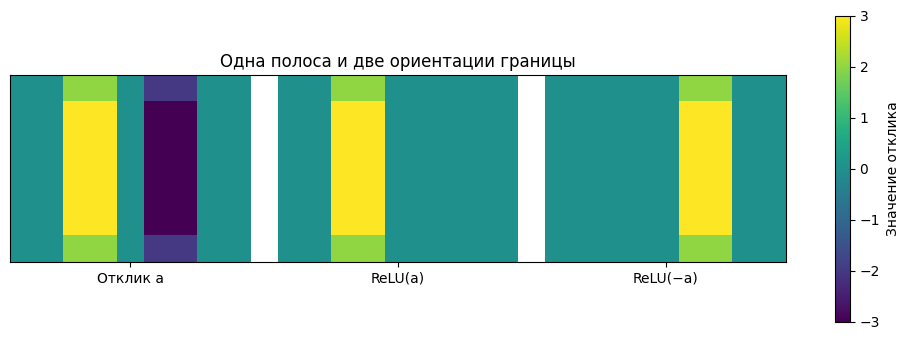

In [14]:
band = torch.zeros(1, 1, 7, 9)
band[:, :, :, 3:6] = 1
response = F.conv2d(band, kernel[None, None], padding=1)
positive = F.relu(response)
opposite = F.relu(-response)

print("Отклики в средней строке", response[0, 0, 3])
print("После ReLU", positive[0, 0, 3])

separator = np.full((7, 1), np.nan)
strip = np.concatenate([
    response[0, 0].numpy(), separator,
    positive[0, 0].numpy(), separator,
    opposite[0, 0].numpy(),
], axis=1)
plt.figure(figsize=(10, 3.5))
plt.imshow(strip, vmin=-3, vmax=3)
plt.xticks([4, 14, 24], ["Отклик a", "ReLU(a)", "ReLU(−a)"])
plt.yticks([])
plt.colorbar(label="Значение отклика")
plt.title("Одна полоса и две ориентации границы")
plt.tight_layout()
plt.show()

### 5.2. Как градиент доходит до первых слоёв

При обратном распространении ошибки производные последовательных преобразований перемножаются.
У сигмоиды производная не больше $1/4$.
У ReLU на положительной ветви она равна единице.
Поэтому сама активация не уменьшает градиент вдоль активного пути.
Это помогает обучению глубоких сетей по сравнению с насыщаемыми активациями [7, 8].

Проведём управляемый опыт.
Возьмём цепочку свёрток $1\times1$ с весами, равными единице, и положительный вход.
Изменять будем только число слоёв и функцию активации.
Посчитаем производную суммы выходов по весу первой свёртки.

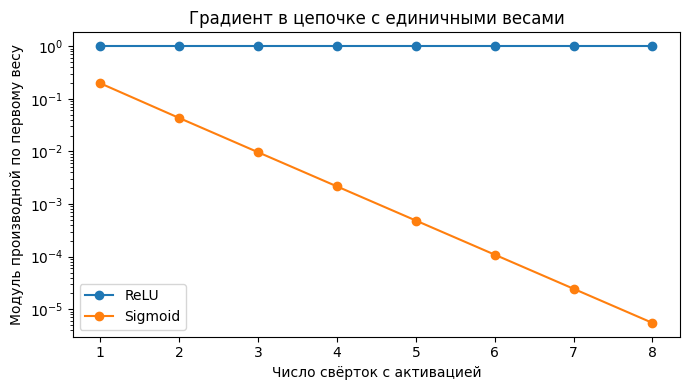

In [15]:
gradient_rows = []
for activation_name, activation_type in [("ReLU", nn.ReLU), ("Sigmoid", nn.Sigmoid)]:
    for depth in range(1, 9):
        layers = []
        for _ in range(depth):
            layer = nn.Conv2d(1, 1, 1, bias=False)
            with torch.no_grad():
                layer.weight.fill_(1)
            layers.extend([layer, activation_type()])
        chain = nn.Sequential(*layers)
        chain(torch.ones(1, 1, 1, 1)).sum().backward()
        gradient_rows.append({
            "Активация": activation_name,
            "Число слоёв": depth,
            "Градиент первого веса": chain[0].weight.grad.abs().item(),
        })
gradient_table = pd.DataFrame(gradient_rows)

plt.figure(figsize=(7, 4))
for name, group in gradient_table.groupby("Активация", sort=False):
    plt.plot(group["Число слоёв"], group["Градиент первого веса"], marker="o", label=name)
plt.yscale("log")
plt.xticks(range(1, 9))
plt.xlabel("Число свёрток с активацией")
plt.ylabel("Модуль производной по первому весу")
plt.title("Градиент в цепочке с единичными весами")
plt.legend()
plt.tight_layout()
plt.show()

В этом опыте ReLU всегда находится на положительной ветви.
В обычной сети часть откликов отрицательна и их градиент через ReLU равен нулю.
Постоянно неактивные нейроны могут перестать обучаться.
Веса других слоёв тоже влияют на величину градиента.

Таким образом, ReLU не гарантирует ускорение любой модели и не устраняет все причины затухания градиента.
Она добавляет нелинейность и не насыщается на положительной ветви.
График выше показывает именно этот механизм, а не измеренную скорость обучения на FashionMNIST.

## 6. BatchNorm2d

### 6.1. Нормирование отдельно для каждого канала

В `BatchNorm2d` среднее и дисперсия вычисляются по осям `(N, H, W)` отдельно для каждого канала [9].
Сам канал при этом не смешивается с соседними каналами.
Форма тензора сохраняется.

$$\widehat x_{n,c,h,w}=\frac{x_{n,c,h,w}-\mu_c}{\sqrt{\sigma_c^2+\varepsilon}},
\qquad y_{n,c,h,w}=\gamma_c\widehat x_{n,c,h,w}+\beta_c.$$

Параметры $\gamma_c$ и $\beta_c$ обучаются вместе с весами сети.
При начальных значениях 1 и 0 получаем центрированные и почти единичные по дисперсии карты.
После обучения их среднее уже не обязано быть нулевым.

In [16]:
bn_input = torch.arange(16, dtype=torch.float32).reshape(2, 2, 2, 2)
bn_input[:, 1] = 3 * bn_input[:, 1] + 20
bn = nn.BatchNorm2d(2)

mean = bn_input.mean(dim=(0, 2, 3), keepdim=True)
variance = bn_input.var(dim=(0, 2, 3), correction=0, keepdim=True)
manual_bn = (bn_input - mean) / torch.sqrt(variance + bn.eps)
bn_output = bn(bn_input)

display(pd.DataFrame({
    "Канал": [0, 1],
    "Среднее до": mean.flatten().numpy(),
    "Дисперсия до": variance.flatten().numpy(),
    "Среднее после": bn_output.mean(dim=(0, 2, 3)).detach().numpy(),
    "Дисперсия после": bn_output.var(dim=(0, 2, 3), correction=0).detach().numpy(),
}))
print("Максимальное расхождение с ручным расчётом", (manual_bn - bn_output).abs().max().item())
print("Обучаемых параметров", sum(p.numel() for p in bn.parameters()))
print("Бегущее среднее", bn.running_mean)

,Канал,Среднее до,Дисперсия до,Среднее после,Дисперсия после
0,0,5.5,17.25,0.000000e+00,0.999999
1,1,48.5,155.25,2.980232e-08,1.000000


Максимальное расхождение с ручным расчётом 1.1920928955078125e-07
Обучаемых параметров 4
Бегущее среднее tensor([0.550, 4.850])


### 6.2. Режимы обучения и оценки

В режиме `train()` BatchNorm использует текущий пакет и обновляет бегущие оценки.
В режиме `eval()` при стандартных настройках используются накопленные оценки [9].
Тогда ответ одного изображения не зависит от других изображений в пакете.
`torch.no_grad()` отключает запись графа, но не переключает эти режимы.

В прямом проходе дисперсия считается с делителем $NHW$.
Для обновления бегущей дисперсии PyTorch использует поправку с делителем $NHW-1$ [9].
Ниже сравним обработку одного изображения отдельно и рядом с сильно отличающимся изображением.

In [17]:
one_image = bn_input[:1]
other_image = bn_input[1:2] + 100
rows = []
for mode in ["train", "eval"]:
    alone_layer = deepcopy(bn)
    together_layer = deepcopy(bn)
    alone_layer.train(mode == "train")
    together_layer.train(mode == "train")
    with torch.no_grad():
        alone = alone_layer(one_image)
        together = together_layer(torch.cat([one_image, other_image]))[:1]
    rows.append({
        "Режим": mode,
        "Максимальное изменение ответа первого изображения": (alone - together).abs().max().item(),
    })
display(pd.DataFrame(rows))

,Режим,Максимальное изменение ответа первого изображения
0,train,2.313649
1,eval,0.000000


BatchNorm меняет масштаб промежуточных значений и часто делает оптимизацию устойчивее [10, 11].
Это не простое преобразование данных к нормальному распределению.
Польза не сводится к утверждению, что распределения внутри сети перестают меняться.

Обычный блок имеет порядок `Conv2d → BatchNorm2d → ReLU`.
Перед BatchNorm смещение свёртки часто отключают через `bias=False`.
Собственный сдвиг у BatchNorm уже есть.
Слишком малые или нерепрезентативные пакеты могут давать шумные оценки.
При оценке качества обязательно переключаем всю модель в `eval()`.

## 7. Две модели для изображений 28 × 28

### 7.1. Соберём свёрточную и полносвязную сети

У FashionMNIST один входной канал и десять классов [12].
В CNN два блока уменьшат карту сначала до $14\times14$, затем до $7\times7$.
После второго блока останется 16 карт.
`Flatten` превратит их в вектор из $16\cdot7\cdot7=784$ значений.

Полносвязная модель сразу развернёт изображение в вектор.
В обеих сетях последний слой выдаёт десять логитов.
Softmax в архитектуру не добавляем.

In [18]:
torch.manual_seed(42)
cnn = nn.Sequential(
    nn.Conv2d(1, 8, kernel_size=3, padding=1, bias=False),
    nn.BatchNorm2d(8),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(8, 16, kernel_size=3, padding=1, bias=False),
    nn.BatchNorm2d(16),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Flatten(),
    nn.Linear(16 * 7 * 7, 32),
    nn.ReLU(),
    nn.Linear(32, 10),
)

torch.manual_seed(42)
mlp = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 10),
)
models = {"CNN": cnn, "MLP": mlp}
cnn

Sequential(
  (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (5): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Flatten(start_dim=1, end_dim=-1)
  (9): Linear(in_features=784, out_features=32, bias=True)
  (10): ReLU()
  (11): Linear(in_features=32, out_features=10, bias=True)
)

### 7.2. Проследим формы и посчитаем параметры

Для свёртки с $g$ группами число весов равно $C_{out}(C_{in}/g)k_Hk_W$.
Если включено смещение, добавляются ещё $C_{out}$ параметров.
У BatchNorm с обучаемыми масштабом и сдвигом есть $2C$ параметров.
Бегущие средние и дисперсии хранятся отдельно и не обучаются градиентным спуском.

В таблице также посчитаем операции умножения с накоплением для свёрток и линейных слоёв.
Одна такая операция обозначается MAC.
Активации, pooling, BatchNorm и служебные операции в этот подсчёт не входят.
Число MAC не заменяет измерение времени.

In [19]:
layer_rows = []
parameter_rows = []
for name, model in models.items():
    model.eval()
    values = torch.zeros(1, 1, 28, 28)
    total_macs = 0
    with torch.no_grad():
        for number, layer in enumerate(model):
            values = layer(values)
            macs = 0
            if isinstance(layer, nn.Conv2d):
                macs = values.numel() * layer.weight[0].numel()
            elif isinstance(layer, nn.Linear):
                macs = values.numel() * layer.in_features
            total_macs += macs
            layer_rows.append({
                "Модель": name, "Шаг": number, "Слой": type(layer).__name__,
                "Форма": tuple(values.shape),
                "Параметры": sum(p.numel() for p in layer.parameters()),
                "MAC": macs,
            })
    parameter_rows.append({
        "Модель": name,
        "Параметры": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "MAC на изображение": total_macs,
    })
layer_table = pd.DataFrame(layer_rows)
parameter_table = pd.DataFrame(parameter_rows).set_index("Модель")
display(layer_table[layer_table["Модель"] == "CNN"].reset_index(drop=True))
display(parameter_table)

,Модель,Шаг,Слой,Форма,Параметры,MAC
0,CNN,0,Conv2d,"(1, 8, 28, 28)",72,56448
1,CNN,1,BatchNorm2d,"(1, 8, 28, 28)",16,0
2,CNN,2,ReLU,"(1, 8, 28, 28)",0,0
3,CNN,3,MaxPool2d,"(1, 8, 14, 14)",0,0
4,CNN,4,Conv2d,"(1, 16, 14, 14)",1152,225792
5,CNN,5,BatchNorm2d,"(1, 16, 14, 14)",32,0
6,CNN,6,ReLU,"(1, 16, 14, 14)",0,0
7,CNN,7,MaxPool2d,"(1, 16, 7, 7)",0,0
8,CNN,8,Flatten,"(1, 784)",0,0
9,CNN,9,Linear,"(1, 32)",25120,25088


,Параметры,MAC на изображение
Модель,,
CNN,26722,307648
MLP,109386,109184


В свёртке один вес используется во многих положениях.
Поэтому малое число параметров не означает малое число вычислений.
У выбранной CNN меньше обучаемых параметров, но больше MAC в свёртках и линейных слоях, чем у выбранной MLP.
Сравним и фактическое время.

### 7.3. Измерим время прямого прохода

Используем искусственный пакет формы `(128, 1, 28, 28)` с тем же типом данных, что у изображений.
Так отдельно измеряется вычисление модели, без чтения файлов и подготовки пакета.
Обе модели работают на одном устройстве в режиме оценки.
Качество распознавания здесь не измеряется.

Перед замером сделаем несколько проходов для прогрева.
Затем повторим замер и возьмём медиану времени на пакет.
При использовании GPU нужно дождаться завершения вычислений [13].

In [20]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

def synchronize(device):
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    elif device.type == "mps":
        torch.mps.synchronize()

sample_batch = torch.rand(128, 1, 28, 28, device=device)
speed_rows = []
for name, model in models.items():
    model.to(device).eval()
    measured_times = []
    with torch.inference_mode():
        for _ in range(10):
            model(sample_batch)
        synchronize(device)
        for _ in range(7):
            synchronize(device)
            started = perf_counter()
            for _ in range(20):
                model(sample_batch)
            synchronize(device)
            measured_times.append((perf_counter() - started) * 1000 / 20)
    median_ms = float(np.median(measured_times))
    speed_rows.append({
        "Модель": name, "Прямой проход, мс/пакет": median_ms,
        "Q25, мс": np.quantile(measured_times, 0.25),
        "Q75, мс": np.quantile(measured_times, 0.75),
        "Изображений/с": 1000 * len(sample_batch) / median_ms,
    })
speed_table = pd.DataFrame(speed_rows).set_index("Модель")
print("Устройство", device, "PyTorch", torch.__version__)
print("CPU", platform.processor() or platform.machine(), "Потоков PyTorch", torch.get_num_threads())
print("Размер пакета", len(sample_batch), "Тип", sample_batch.dtype)
display(speed_table.round(3))

Устройство cpu PyTorch 2.11.0+cpu
CPU x86_64 Потоков PyTorch 2
Размер пакета 128 Тип torch.float32


,"Прямой проход, мс/пакет","Q25, мс","Q75, мс",Изображений/с
Модель,,,,
CNN,10.596,10.470,10.777,12080.322
MLP,0.341,0.338,0.353,375667.599


Это замер двух конкретных архитектур при одном размере пакета.
На другом устройстве соотношение времени может измениться.
Время обучения будет включать ещё вычисление градиентов и обновление весов.
Ниже измерим его отдельно.

## 8. Данные FashionMNIST

### 8.1. Загрузим изображения

В исходном наборе 60 000 обучающих и 10 000 тестовых изображений одежды [12].
Каждое изображение имеет размер $28\times28$ и один канал.
Яркости хранятся целыми числами от 0 до 255.

`FashionMNIST` прочитает файлы стандартного формата.
В качестве адреса загрузки используем каталог официального репозитория набора.

In [21]:
from torchvision.datasets import FashionMNIST

FashionMNIST.mirrors = [
    "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/",
]
fashion_train = FashionMNIST(root="data", train=True, download=True)
fashion_test = FashionMNIST(root="data", train=False, download=True)

images = fashion_train.data.numpy()
labels = fashion_train.targets.numpy()
test_images = fashion_test.data.numpy()
test_labels = fashion_test.targets.numpy()
class_names = np.array([
    "Футболка", "Брюки", "Пуловер", "Платье", "Пальто",
    "Сандалии", "Рубашка", "Кроссовки", "Сумка", "Ботинки",
])

100%|██████████| 26.4M/26.4M [00:00<00:00, 335MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 28.0MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 16.8MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 6.64MB/s]


### 8.2. Посмотрим на классы

Покажем по одному изображению каждого класса.
Название берём по исходной метке.

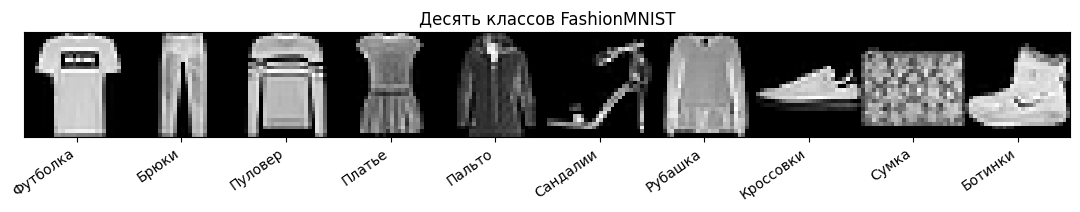

In [22]:
indices = [np.flatnonzero(labels == label)[0] for label in range(10)]
image_strip = np.concatenate([images[index] for index in indices], axis=1)
plt.figure(figsize=(11, 3.2))
plt.imshow(image_strip, cmap="gray", vmin=0, vmax=255)
plt.xticks(28 * np.arange(10) + 13.5, class_names, rotation=35, ha="right")
plt.yticks([])
plt.title("Десять классов FashionMNIST")
plt.tight_layout()
plt.show()

### 8.3. Подготовим одинаковые части для двух моделей

Для короткого опыта выберем 15 000 изображений из исходной обучающей части.
Из них 12 000 пойдут на обучение, а 3000 — на валидацию.
При обоих разбиениях сохраним доли классов.
Все 10 000 изображений официального теста оставим для итоговой оценки.

Размер подвыборки и пять эпох задаём до сравнения.
Обе модели получат одни и те же изображения в одинаковом порядке пакетов.
Это сравнение выбранных архитектур, а не поиск лучшего возможного результата для каждого семейства моделей.

In [23]:
selected_indices, _ = train_test_split(
    np.arange(len(images)), train_size=15000,
    stratify=labels, random_state=42,
)
train_indices, valid_indices = train_test_split(
    selected_indices, test_size=0.2,
    stratify=labels[selected_indices], random_state=42,
)

display(pd.DataFrame({
    "Часть": ["train", "valid", "test"],
    "Изображений": [len(train_indices), len(valid_indices), len(test_images)],
    "Источник": ["Обучающий файл", "Обучающий файл", "Официальный тест"],
}))

,Часть,Изображений,Источник
0,train,12000,Обучающий файл
1,valid,3000,Обучающий файл
2,test,10000,Официальный тест


### 8.4. Dataset и DataLoader

Один объект возвращает тензор `(1, 28, 28)` и целочисленную метку.
В пакете появится первая ось `N`.
Деление на 255 переводит пиксели в диапазон от 0 до 1.
Других преобразований и аугментаций в этом сравнении нет.

Загрузчик для обучения создадим заново перед каждой моделью с одинаковым генератором перестановок.
Для валидации, теста и итоговой оценки обучающей части перемешивание не нужно.

In [24]:
class ImageDataset(Dataset):
    def __init__(self, images, labels):
        self.images = images
        self.labels = labels

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image = torch.tensor(self.images[index], dtype=torch.float32).unsqueeze(0) / 255
        label = torch.tensor(self.labels[index], dtype=torch.long)
        return image, label

train_dataset = ImageDataset(images[train_indices], labels[train_indices])
valid_dataset = ImageDataset(images[valid_indices], labels[valid_indices])
test_dataset = ImageDataset(test_images, test_labels)

valid_loader = DataLoader(valid_dataset, batch_size=128, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, num_workers=0)
train_eval_loader = DataLoader(train_dataset, batch_size=128, shuffle=False, num_workers=0)

batch_images, batch_labels = next(iter(valid_loader))
print("Изображения", tuple(batch_images.shape), batch_images.dtype)
print("Метки", tuple(batch_labels.shape), batch_labels.dtype)

Изображения (128, 1, 28, 28) torch.float32
Метки (128,) torch.int64


## 9. Обучение и валидация

### 9.1. Функция потерь и оптимизатор

`CrossEntropyLoss` получает логиты формы `(N, 10)` и метки формы `(N,)` с типом `long` [14].
Вероятности отдельно вычислять не нужно.
Для каждой модели создадим собственный `Adam` с шагом $10^{-3}$.

Сначала пройдём обучающие пакеты, затем валидационные.
Ошибка эпохи будет средней по изображениям, а не простым средним ошибок пакетов.
Сохраним состояние с наименьшей валидационной ошибкой.
В `state_dict` входят и веса, и бегущие статистики BatchNorm.

In [25]:
loss_fn = nn.CrossEntropyLoss()
histories = {}
best_epochs = {}

for name, model in models.items():
    torch.manual_seed(42)
    train_loader = DataLoader(
        train_dataset, batch_size=128, shuffle=True, num_workers=0,
        generator=torch.Generator().manual_seed(42),
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = []
    best_valid_loss = float("inf")
    best_state = deepcopy(model.state_dict())

    for epoch in range(1, 6):
        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        synchronize(device)
        started = perf_counter()

        for x_batch, y_batch in train_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            logits = model(x_batch)
            loss = loss_fn(logits, y_batch)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(y_batch)
            train_correct += (logits.argmax(dim=1) == y_batch).sum().item()

        synchronize(device)
        train_seconds = perf_counter() - started
        model.eval()
        valid_loss_sum = 0.0
        valid_correct = 0
        with torch.no_grad():
            for x_batch, y_batch in valid_loader:
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                logits = model(x_batch)
                valid_loss_sum += loss_fn(logits, y_batch).item() * len(y_batch)
                valid_correct += (logits.argmax(dim=1) == y_batch).sum().item()

        valid_loss = valid_loss_sum / len(valid_dataset)
        history.append({
            "epoch": epoch,
            "train_loss": train_loss_sum / len(train_dataset),
            "valid_loss": valid_loss,
            "train_accuracy": train_correct / len(train_dataset),
            "valid_accuracy": valid_correct / len(valid_dataset),
            "train_seconds": train_seconds,
        })
        if valid_loss < best_valid_loss:
            best_valid_loss = valid_loss
            best_state = deepcopy(model.state_dict())
            best_epochs[name] = epoch

    model.load_state_dict(best_state)
    model.eval()
    histories[name] = pd.DataFrame(history)
    print(name, "лучшая эпоха", best_epochs[name])
    display(histories[name].round(4))

CNN лучшая эпоха 5


,epoch,train_loss,valid_loss,train_accuracy,valid_accuracy,train_seconds
0,1,0.8664,0.4932,0.7262,0.8253,2.2221
1,2,0.4496,0.4063,0.8435,0.8553,2.1443
2,3,0.3828,0.3785,0.8635,0.8667,2.1409
3,4,0.3450,0.3587,0.8789,0.8697,2.1196
4,5,0.3199,0.3498,0.8861,0.8743,2.1966


MLP лучшая эпоха 4


,epoch,train_loss,valid_loss,train_accuracy,valid_accuracy,train_seconds
0,1,1.0191,0.6329,0.6512,0.7780,0.6394
1,2,0.5770,0.5428,0.7950,0.8127,0.6251
2,3,0.5044,0.5078,0.8199,0.8140,0.6258
3,4,0.4695,0.4747,0.8361,0.8367,0.6551
4,5,0.4324,0.4867,0.8499,0.8243,0.6325


### 9.2. Графики обучения

На обучающей кривой усредняются ответы, полученные во время изменения весов.
На валидационной кривой веса уже фиксированы на конец эпохи.
У CNN дополнительно различается режим BatchNorm.
Поэтому итоговую обучающую метрику лучшей модели далее посчитаем отдельным проходом в `eval()`.

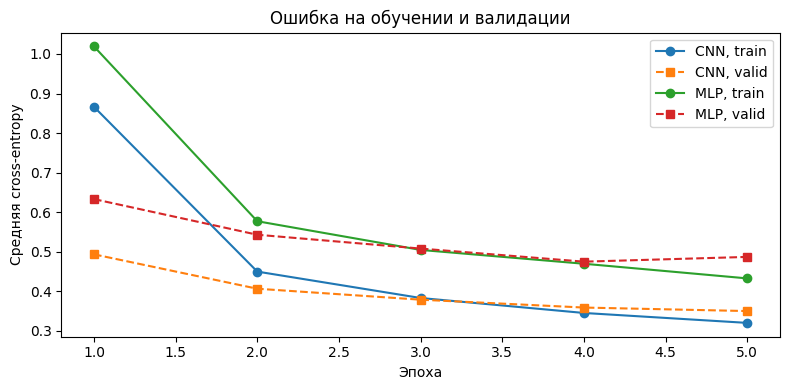

In [26]:
plt.figure(figsize=(8, 4))
for name, history in histories.items():
    plt.plot(history["epoch"], history["train_loss"], marker="o", label=f"{name}, train")
    plt.plot(history["epoch"], history["valid_loss"], marker="s", linestyle="--", label=f"{name}, valid")
plt.xlabel("Эпоха")
plt.ylabel("Средняя cross-entropy")
plt.title("Ошибка на обучении и валидации")
plt.legend()
plt.tight_layout()
plt.show()

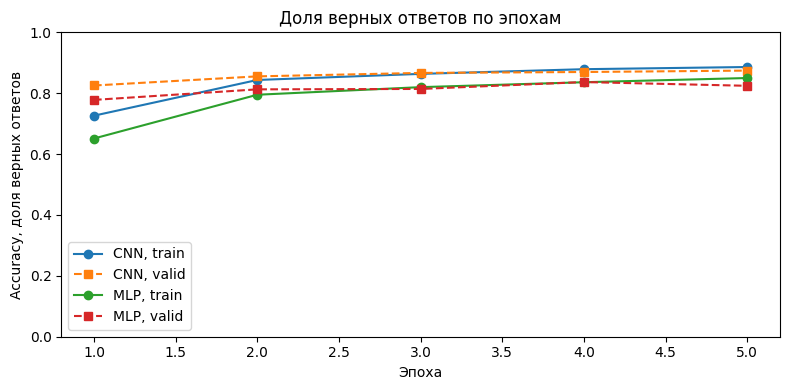

In [27]:
plt.figure(figsize=(8, 4))
for name, history in histories.items():
    plt.plot(history["epoch"], history["train_accuracy"], marker="o", label=f"{name}, train")
    plt.plot(history["epoch"], history["valid_accuracy"], marker="s", linestyle="--", label=f"{name}, valid")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy, доля верных ответов")
plt.ylim(0, 1)
plt.title("Доля верных ответов по эпохам")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Качество, параметры и время

### 10.1. Оценим лучшие состояния на train и test

Для обеих моделей посчитаем accuracy и macro-F1.
В macro-F1 каждый класс получает одинаковый вес.
Сохраним тестовые ответы в порядке исходных изображений.

Тест не участвует в выборе эпохи или архитектуры.
Время обучения ниже включает загрузчик, перенос пакетов, прямой и обратный проходы, обновление весов и накопление метрик.
Загрузка файлов, валидация и рисование графиков в него не входят.

In [28]:
metric_rows = []
test_predictions = {}
test_probabilities = {}

for name, model in models.items():
    model.eval()
    for split_name, loader in [("train", train_eval_loader), ("test", test_loader)]:
        all_targets = []
        all_logits = []
        loss_sum = 0.0
        with torch.inference_mode():
            for x_batch, y_batch in loader:
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                logits = model(x_batch)
                loss_sum += loss_fn(logits, y_batch).item() * len(y_batch)
                all_logits.append(logits.cpu())
                all_targets.append(y_batch.cpu())
        targets = torch.cat(all_targets).numpy()
        logits = torch.cat(all_logits)
        predictions = logits.argmax(dim=1).numpy()
        metric_rows.append({
            "Модель": name, "Часть": split_name,
            "Cross-entropy": loss_sum / len(loader.dataset),
            "Accuracy": accuracy_score(targets, predictions),
            "Macro-F1": f1_score(targets, predictions, labels=range(10), average="macro", zero_division=0),
        })
        if split_name == "test":
            test_predictions[name] = predictions
            test_probabilities[name] = logits.softmax(dim=1).numpy()
metrics = pd.DataFrame(metric_rows)
display(metrics.round(4))

,Модель,Часть,Cross-entropy,Accuracy,Macro-F1
0,CNN,train,0.2983,0.8936,0.8920
1,CNN,test,0.3826,0.8649,0.8622
2,MLP,train,0.4367,0.8470,0.8483
3,MLP,test,0.4963,0.8263,0.8281


### 10.2. Сведём сравнение в одну таблицу

Число параметров описывает размер обучаемой части модели.
Время прямого прохода взято из опыта с искусственным пакетом той же формы.
Качество рассчитано на настоящих тестовых изображениях.
Все три характеристики отвечают на разные вопросы.

Один опыт с одной инициализацией не устанавливает преимущество всех CNN над всеми MLP.
Для устойчивого сравнения потребовались бы повторения с разными инициализациями и отдельный подбор параметров по валидации.

,Параметры,MAC на изображение,"Прямой проход, мс/пакет","Обучение, с",Лучшая эпоха,Accuracy,Macro-F1
Модель,,,,,,,
CNN,26722,307648,10.5957,10.8236,5,0.8649,0.8622
MLP,109386,109184,0.3407,3.1779,4,0.8263,0.8281


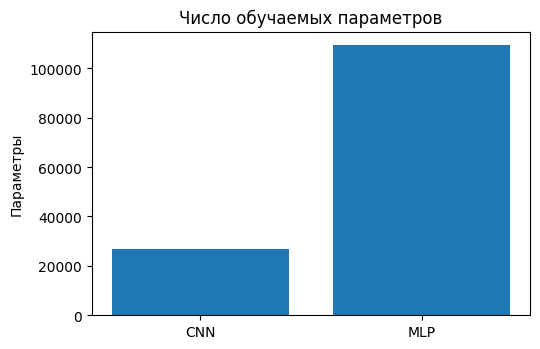

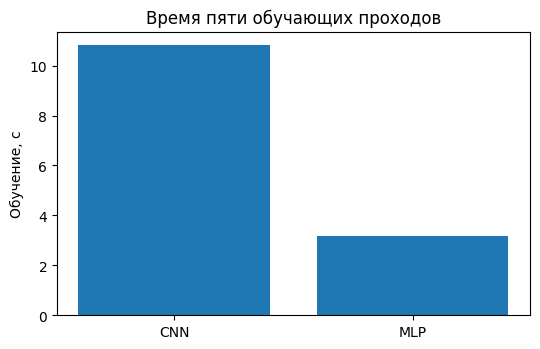

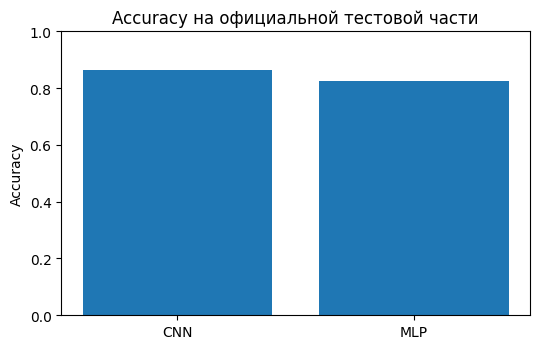

In [29]:
comparison = parameter_table.join(speed_table[["Прямой проход, мс/пакет"]])
comparison["Обучение, с"] = pd.Series({
    name: history["train_seconds"].sum() for name, history in histories.items()
})
comparison["Лучшая эпоха"] = pd.Series(best_epochs)
comparison = comparison.join(
    metrics[metrics["Часть"] == "test"].set_index("Модель")[["Accuracy", "Macro-F1"]]
)
display(comparison.round(4))

for column, title in [
    ("Параметры", "Число обучаемых параметров"),
    ("Обучение, с", "Время пяти обучающих проходов"),
    ("Accuracy", "Accuracy на официальной тестовой части"),
]:
    plt.figure(figsize=(5.5, 3.6))
    plt.bar(comparison.index, comparison[column])
    plt.ylabel(column)
    plt.title(title)
    if column == "Accuracy":
        plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

## 11. Посмотрим на ответы CNN

### 11.1. Матрица ошибок

Строки соответствуют правильным классам, столбцы — предсказанным.
Нормируем каждую строку на число изображений её класса.
Так можно сравнить, какие классы путаются чаще.

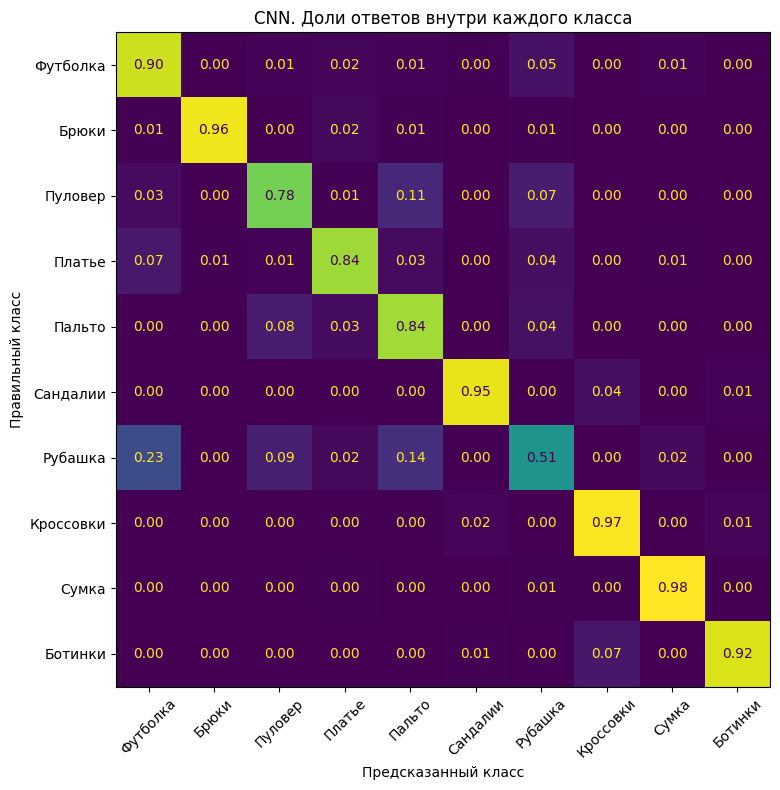

In [30]:
fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(111)
ConfusionMatrixDisplay.from_predictions(
    test_labels, test_predictions["CNN"], labels=np.arange(10),
    display_labels=class_names, normalize="true", values_format=".2f",
    ax=ax, colorbar=False, xticks_rotation=45,
)
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Правильный класс")
ax.set_title("CNN. Доли ответов внутри каждого класса")
plt.tight_layout()
plt.show()

### 11.2. Одинаковые изображения и ответы двух моделей

Выберем первые восемь ошибок CNN в порядке тестовой части.
Для тех же изображений покажем ответы MLP.
Это подборка ошибок, а не случайная выборка для оценки общей точности.

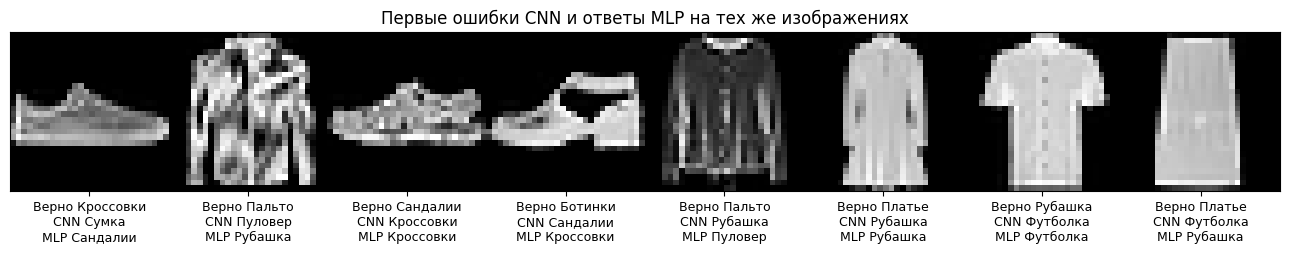

In [31]:
error_indices = np.flatnonzero(test_predictions["CNN"] != test_labels)[:8]
if len(error_indices) == 0:
    print("Ошибок CNN на этой тестовой части нет.")
else:
    strip = np.concatenate([test_images[index] for index in error_indices], axis=1)
    captions = [
        f"Верно {class_names[test_labels[index]]}\n"
        f"CNN {class_names[test_predictions['CNN'][index]]}\n"
        f"MLP {class_names[test_predictions['MLP'][index]]}"
        for index in error_indices
    ]
    plt.figure(figsize=(13, 3.7))
    plt.imshow(strip, cmap="gray", vmin=0, vmax=255)
    plt.xticks(28 * np.arange(len(error_indices)) + 13.5, captions, fontsize=9)
    plt.yticks([])
    plt.title("Первые ошибки CNN и ответы MLP на тех же изображениях")
    plt.tight_layout()
    plt.show()

### 11.3. Обученные ядра и карты признаков

У первой свёртки восемь выходных каналов и один входной.
Поэтому каждое её ядро можно показать как матрицу $3\times3$.
Затем посмотрим на выход первого блока до pooling.
Это карты после свёртки, BatchNorm и ReLU.

Карта показывает пространственный отклик одного канала.
Она не является вероятностью класса и сама по себе не объясняет всё решение сети.

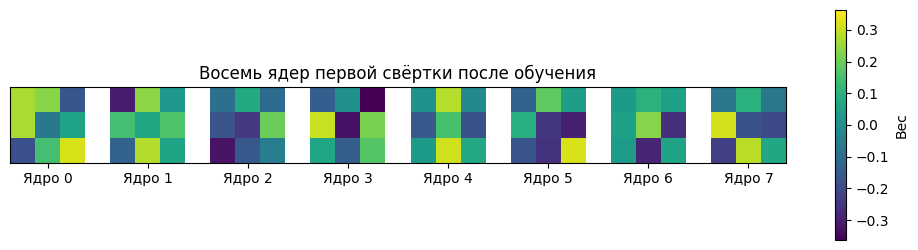

In [32]:
weights = cnn[0].weight.detach().cpu().numpy()[:, 0]
separator = np.full((3, 1), np.nan)
parts = []
for index, weight in enumerate(weights):
    if index:
        parts.append(separator)
    parts.append(weight)
weight_strip = np.concatenate(parts, axis=1)
limit = max(float(np.abs(weights).max()), 1e-8)

plt.figure(figsize=(10, 2.6))
plt.imshow(weight_strip, vmin=-limit, vmax=limit)
plt.xticks(4 * np.arange(8) + 1, [f"Ядро {i}" for i in range(8)])
plt.yticks([])
plt.colorbar(label="Вес")
plt.title("Восемь ядер первой свёртки после обучения")
plt.tight_layout()
plt.show()

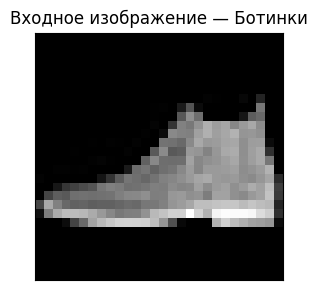

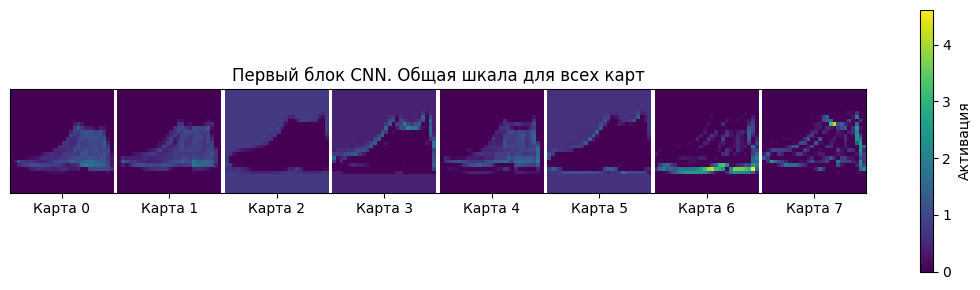

In [33]:
image, label = test_dataset[0]
cnn.eval()
with torch.inference_mode():
    maps = cnn[:3](image.unsqueeze(0).to(device))[0].cpu().numpy()

plt.figure(figsize=(3, 3))
plt.imshow(image[0].numpy(), cmap="gray", vmin=0, vmax=1)
plt.title(f"Входное изображение — {class_names[label.item()]}")
plt.xticks([])
plt.yticks([])
plt.tight_layout()
plt.show()

parts = []
for index, feature_map in enumerate(maps):
    if index:
        parts.append(np.full((28, 1), np.nan))
    parts.append(feature_map)
feature_strip = np.concatenate(parts, axis=1)
plt.figure(figsize=(11, 3))
plt.imshow(feature_strip, vmin=0, vmax=max(float(maps.max()), 1e-8))
plt.xticks(29 * np.arange(8) + 13.5, [f"Карта {i}" for i in range(8)])
plt.yticks([])
plt.colorbar(label="Активация")
plt.title("Первый блок CNN. Общая шкала для всех карт")
plt.tight_layout()
plt.show()

## Краткая памятка

| Слой | Что изменяется |
|---|---|
| `Conv2d` | Локальные признаки, число карт и иногда их размер |
| `ReLU` | Значения откликов, форма сохраняется |
| `MaxPool2d` / `AvgPool2d` | Пространственная детализация, каналы не смешиваются |
| `BatchNorm2d` | Масштаб и сдвиг каждого канала, форма сохраняется |
| `AdaptiveAvgPool2d` | Пространственный размер приводится к заданному |
| `Flatten` | Карты превращаются в один вектор на изображение |
| `Linear` | Вектор признаков преобразуется в новый вектор или логиты |

Для изображения нужен порядок осей `C, H, W`, для пакета — `N, C, H, W`.
Вход свёртки не разворачиваем в плоский вектор.
Число входных каналов следующего слоя должно совпадать с числом выходных каналов предыдущего.
При оценке используем `model.eval()` и отключаем запись графа.

## Источники

[1] [PyTorch. Conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html).

[2] [PyTorch. Functional conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.conv2d.html).

[3] [Howard et al. MobileNets](https://arxiv.org/abs/1704.04861).

[4] [PyTorch. MaxPool2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html).

[5] [PyTorch. AvgPool2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html).

[6] [PyTorch. AdaptiveAvgPool2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.AdaptiveAvgPool2d.html).

[7] [PyTorch. ReLU](https://docs.pytorch.org/docs/stable/generated/torch.nn.ReLU.html).

[8] [Glorot, Bordes, Bengio. Deep Sparse Rectifier Neural Networks](https://proceedings.mlr.press/v15/glorot11a.html).

[9] [PyTorch. BatchNorm2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html).

[10] [Ioffe, Szegedy. Batch Normalization](https://arxiv.org/abs/1502.03167).

[11] [Santurkar et al. How Does Batch Normalization Help Optimization?](https://arxiv.org/abs/1805.11604).

[12] [FashionMNIST. Официальный репозиторий](https://github.com/zalandoresearch/fashion-mnist).

[13] [PyTorch. Измерение производительности](https://docs.pytorch.org/tutorials/recipes/recipes/benchmark.html).

[14] [PyTorch. CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html).